# 遗传算法运行结果分析

本 notebook 对 `results/genetic_algorithm_data.csv` 做可视化分析。该文件由
`src/python/ga_lorentzian.py`（或 C 版 `src/c/genetic_algorithm.c`）生成，记录
**每一代、每一个个体**的四个参数与适应度：

| 列名 | 含义 |
| --- | --- |
| `Generation` | 迭代代数（0 ~ 500；第 500 代为最终种群） |
| `Individual` | 当前代中个体的编号（0 ~ 99） |
| `Y0`, `B`, `lambda0`, `delta_lambda_L` | 洛伦兹函数的四个参数 |
| `Fitness` | 适应度 = 逐点相对误差的平均值（越小越好） |

运行前请先在仓库根目录执行：

```bash
python src/python/ga_lorentzian.py        # 或者运行 C 版生成同样的 CSV
```

> 整理前（数据读取有误时）的分析与当时的图见
> [`archive/analyse_genetique_original.ipynb`](archive/analyse_genetique_original.ipynb)。


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D  # noqa: F401  注册 3D 投影

plt.rcParams["figure.dpi"] = 110

# 读取遗传算法输出（相对于本 notebook 所在目录）
df = pd.read_csv("../results/genetic_algorithm_data.csv")
print("size:", df.shape)
print("generations:", df["Generation"].nunique(),
      "| individuals per generation:", df.groupby("Generation").size().max())
df.head()


size: (50100, 7)
generations: 501 | individuals per generation: 100


,Generation,Individual,Y0,B,lambda0,delta_lambda_L,Fitness
0,0,0,0.057863,58.900815,6569.680624,6.752220,1.028616
1,0,1,0.044465,71.714286,6570.963927,1.651967,4.457290
2,0,2,0.221809,71.711264,6561.413160,4.516739,0.933236
3,0,3,0.155972,66.659597,6557.274087,4.295785,1.097407
4,0,4,0.167592,31.865932,6569.894253,1.205176,2.448048


## 1. 适应度演化

适应度取逐点相对误差的平均值，因此**越小越好**。左图为每代最优与平均适应度，
右图为对数坐标下的最优适应度（便于观察后期的微小改进）。

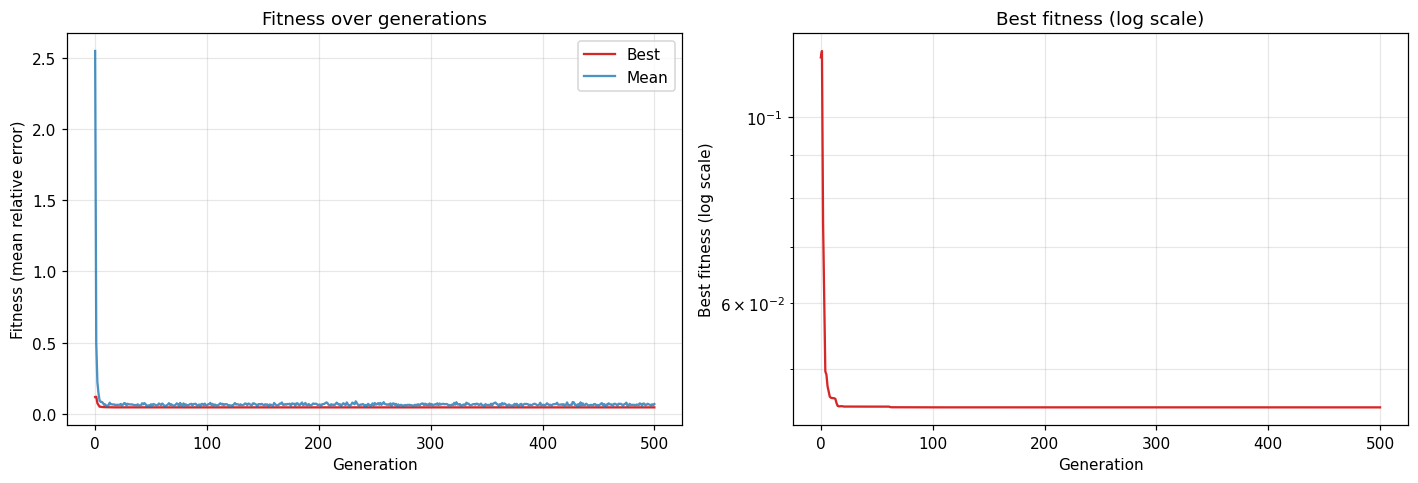

In [2]:
best_fitness = df.groupby("Generation")["Fitness"].min()
mean_fitness = df.groupby("Generation")["Fitness"].mean()

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

axes[0].plot(best_fitness.index, best_fitness.values, color="tab:red", label="Best")
axes[0].plot(mean_fitness.index, mean_fitness.values, color="tab:blue",
             alpha=0.8, label="Mean")
axes[0].set_xlabel("Generation")
axes[0].set_ylabel("Fitness (mean relative error)")
axes[0].set_title("Fitness over generations")
axes[0].grid(alpha=0.3)
axes[0].legend()

axes[1].semilogy(best_fitness.index, best_fitness.values, color="tab:red")
axes[1].set_xlabel("Generation")
axes[1].set_ylabel("Best fitness (log scale)")
axes[1].set_title("Best fitness (log scale)")
axes[1].grid(which="both", alpha=0.3)

plt.tight_layout()
plt.show()


## 2. 每代最优个体的参数

四个参数随代数的变化。可以看到算法在前几十代就基本收敛，之后只剩下变异带来的微小抖动。

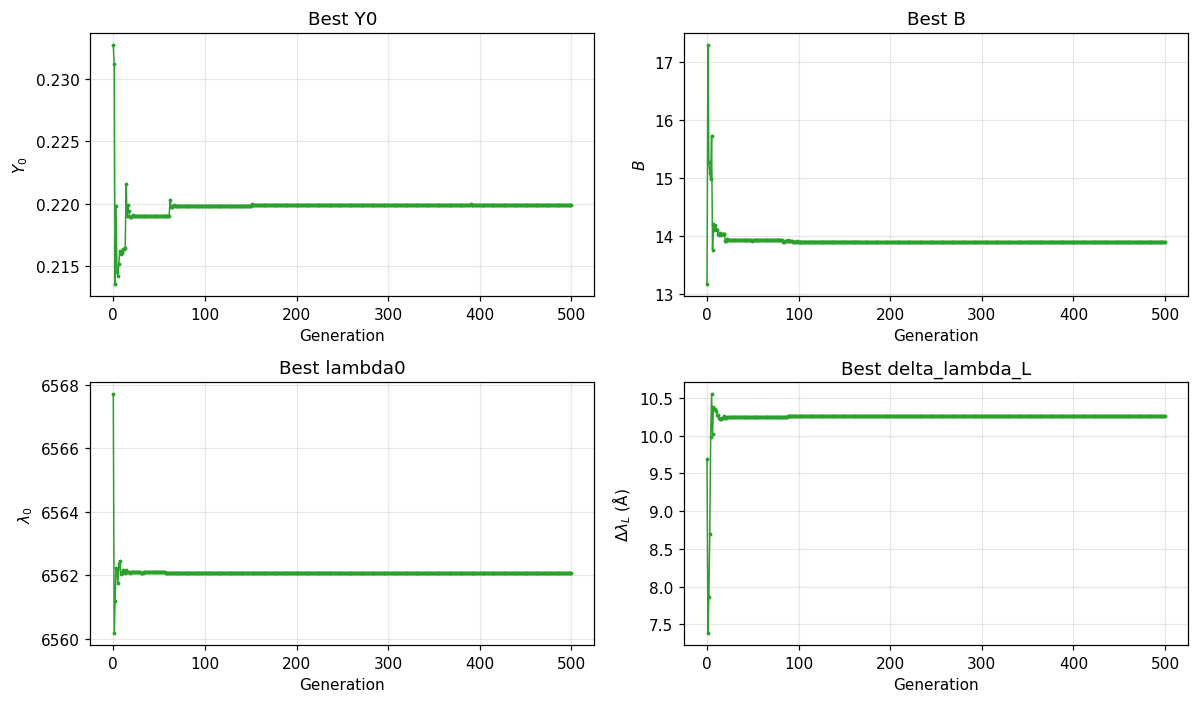

In [3]:
best_rows = df.loc[df.groupby("Generation")["Fitness"].idxmin()]
params = ["Y0", "B", "lambda0", "delta_lambda_L"]
labels = [r"$Y_0$", r"$B$", r"$\lambda_0$", r"$\Delta\lambda_L$ (Å)"]

fig, axes = plt.subplots(2, 2, figsize=(11, 6.5))
for ax, name, label in zip(axes.ravel(), params, labels):
    ax.plot(best_rows["Generation"], best_rows[name], color="tab:green",
            marker=".", markersize=3, linewidth=1)
    ax.set_xlabel("Generation")
    ax.set_ylabel(label)
    ax.set_title(f"Best {name}")
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()


## 3. 参数在每一代中的分布

把每一代 100 个个体的参数值划分成若干区间，统计每个区间的个体数，画成三维散点图：
X 轴为参数值，Y 轴为代数，Z 轴为该区间内的个体数。

算法前期个体分散在整个搜索空间；随着代数增加，绝大多数个体聚集到最优值附近，
说明种群确实在向最优解收敛。

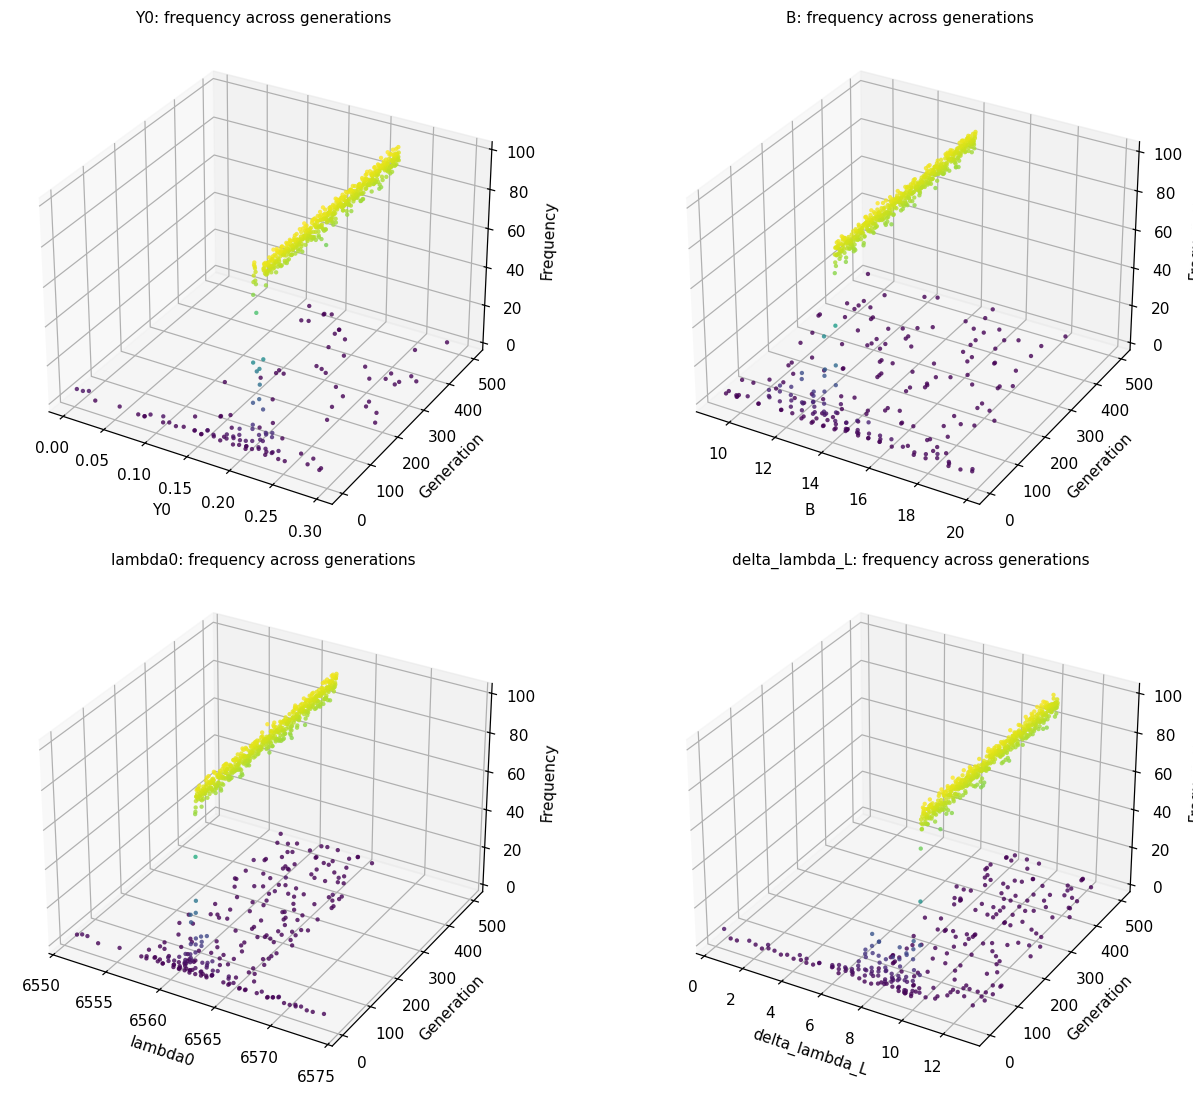

In [4]:
param_bins = {
    "Y0": (0.0, 0.3, 40),
    "B": (1.0, 20.0, 40),
    "lambda0": (6550.0, 6575.0, 50),
    "delta_lambda_L": (0.0, 13.0, 40),
}

fig = plt.figure(figsize=(13, 10))
for i, name in enumerate(params, start=1):
    ax = fig.add_subplot(2, 2, i, projection="3d")
    start, end, nbin = param_bins[name]
    bins = np.linspace(start, end, nbin + 1)
    centers = 0.5 * (bins[:-1] + bins[1:])

    xs, ys, zs = [], [], []
    for gen in sorted(df["Generation"].unique()):
        values = df.loc[df["Generation"] == gen, name].to_numpy()
        counts, _ = np.histogram(values, bins=bins)
        for x, count in zip(centers, counts):
            if count > 2:      # 只显示出现次数大于 2 的区间
                xs.append(x)
                ys.append(gen)
                zs.append(count)

    ax.scatter(xs, ys, zs, c=zs, cmap="viridis", s=8, alpha=0.8, edgecolors="none")
    ax.set_xlabel(name)
    ax.set_ylabel("Generation")
    ax.set_zlabel("Frequency")
    ax.set_title(f"{name}: frequency across generations", fontsize=10)

plt.tight_layout()
plt.show()


## 4. 参数与适应度的关系

每个点代表一个个体。适应度小的个体集中在参数最优值附近，形成一条"窄带"。

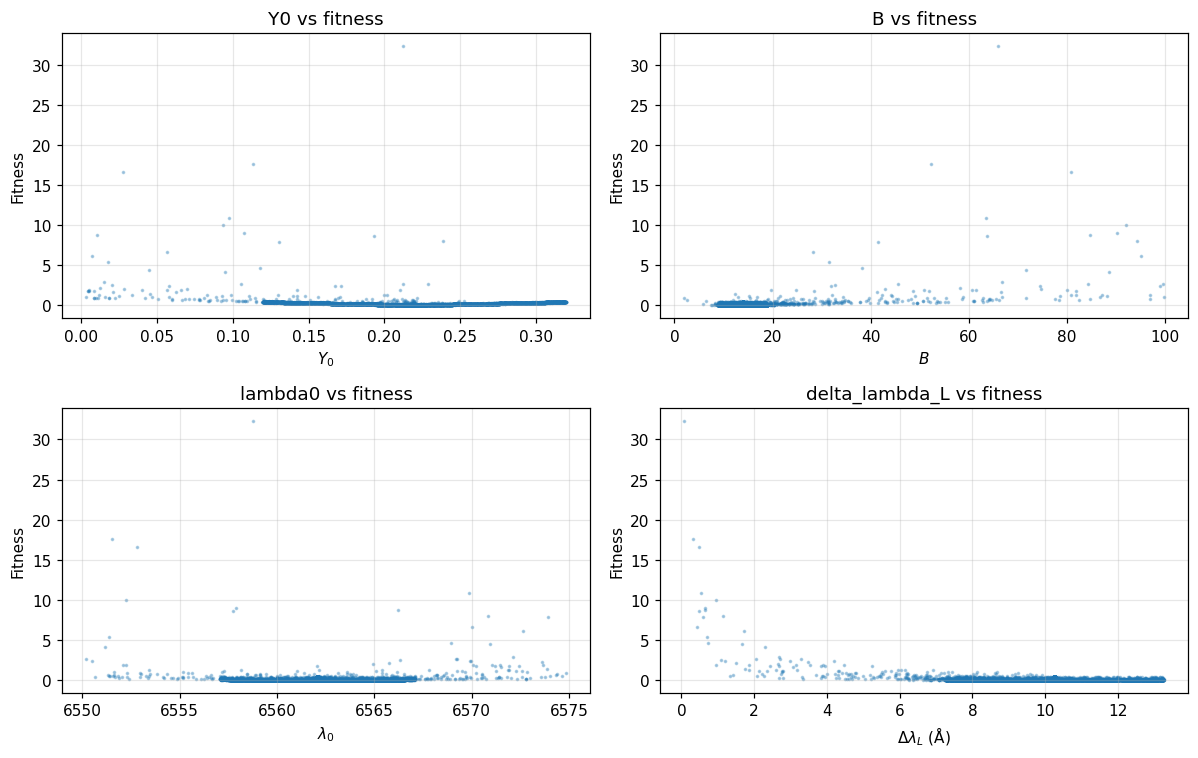

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(11, 7))
for ax, name, label in zip(axes.ravel(), params, labels):
    ax.scatter(df[name], df["Fitness"], s=2, alpha=0.3, color="tab:blue")
    ax.set_xlabel(label)
    ax.set_ylabel("Fitness")
    ax.set_title(f"{name} vs fitness")
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()


## 5. 最优拟合结果

取整轮运行中适应度最小的个体，画出洛伦兹拟合曲线与残差。

> 说明：数据文件第三列是噪声-free 的参考曲线，这里一并画出作为对照；
> 遗传算法本身只使用前两列（波长、实测强度）。

Y0 = 0.21992, B = 13.90698, lambda0 = 6562.07706 A, delta_lambda_L = 10.25711 A
RMSE = 0.014122
electron density Ne = 1.14936e+23 m^-3


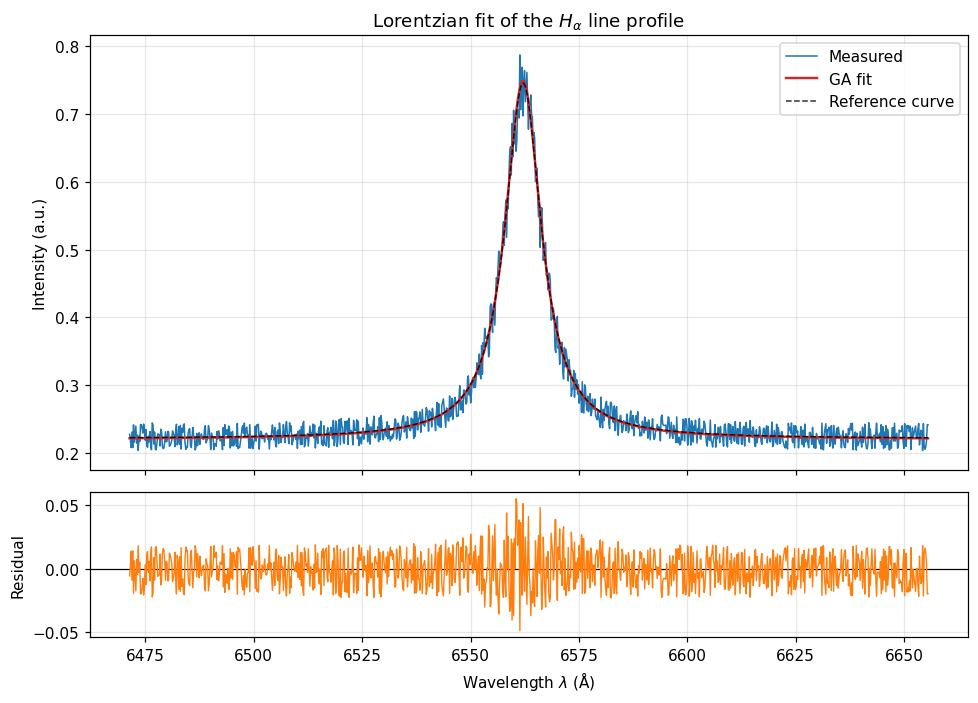

In [6]:
data = np.loadtxt("../data/Data_Genetique.txt")
wavelength, intensity, reference = data[:, 0], data[:, 1], data[:, 2]

best = df.loc[df["Fitness"].idxmin()]
y0, B, lam0, dlam = (best[name] for name in params)

def lorentzian(wavelength, y0, b, lam0, dlam):
    return y0 + b / ((wavelength - lam0) ** 2 + (dlam / 2.0) ** 2)

model = lorentzian(wavelength, y0, B, lam0, dlam)
residual = model - intensity
rmse = np.sqrt(np.mean(residual ** 2))
ne = 10.0 ** (21.78515 + 1.2614 * np.log10(dlam))

print(f"Y0 = {y0:.5f}, B = {B:.5f}, lambda0 = {lam0:.5f} A, "
      f"delta_lambda_L = {dlam:.5f} A")
print(f"RMSE = {rmse:.6f}")
print(f"electron density Ne = {ne:.5e} m^-3")

fig, axes = plt.subplots(2, 1, figsize=(9, 6.5), sharex=True,
                         gridspec_kw={"height_ratios": [3, 1]})
axes[0].plot(wavelength, intensity, color="tab:blue", linewidth=1, label="Measured")
axes[0].plot(wavelength, model, color="tab:red", linewidth=1.6, label="GA fit")
axes[0].plot(wavelength, reference, color="black", linestyle="--",
             linewidth=1, alpha=0.8, label="Reference curve")
axes[0].set_ylabel("Intensity (a.u.)")
axes[0].set_title("Lorentzian fit of the $H_\\alpha$ line profile")
axes[0].grid(alpha=0.3)
axes[0].legend()

axes[1].axhline(0, color="black", linewidth=0.8)
axes[1].plot(wavelength, residual, color="tab:orange", linewidth=0.9)
axes[1].set_xlabel(r"Wavelength $\lambda$ (Å)")
axes[1].set_ylabel("Residual")
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()


## 6. 小结

* 遗传算法在前 20 代左右就把平均适应度从 > 1 降到 0.05 附近，之后主要由变异提供局部搜索；
* 最优个体的四个参数与数据第三列参考曲线对应的参数几乎一致（差异 < 1%）；
* 由半高宽 $\Delta\lambda_L$ 换算得到电子密度
  $n_e = 10^{21.78515 + 1.2614\log_{10}\Delta\lambda_L}\approx 1.15\times10^{23}\ \mathrm{m^{-3}}$。

> 注意：本次运行使用了固定随机种子（`RANDOM_SEED = 12345`），所以结果可复现；
> 更换种子后最优参数会有千分之一量级的差别。
